# EURIBOR 6M curve: dual-curve bootstrap on €STR discounting

Companion notebook of the report `Rapports/Euribor/euribor_curve_report.tex` (its section numbers are given in the
headings; `Rapports/Euribor/make_figures.py` extracts the figures from this notebook).

The EURIBOR 6M **projection** curve gives the expected 6-month fixings of the floating leg of euro swaps; the cash flows
are **discounted on the €STR curve** of the companion notebook `estr_curve.ipynb`. Pipeline:
1. Rebuild the €STR discount curve (same construction as `estr_curve.ipynb`: meeting steps up to 2 years, raw beyond).
2. Measure the EURIBOR - €STR basis from the published fixings (monthly averages, ECB).
3. Build **proxy** EURIBOR 6M quotes (6M fixing, FRAs, IRS): EURIBOR swap quotes and daily fixings are not free.
4. Single-curve bootstrap (baseline), then dual-curve bootstrap with three interpolations, and validation (including an
   independent repricing with QuantLib).
5. Single-curve vs dual-curve prices, the EURIBOR 3M curve and the 3M/6M tenor basis, par-point risk to both curves.

> **Real vs proxy.** EURIBOR monthly averages, €STR fixings and the AAA curve are official ECB data. The €STR OIS and the
> EURIBOR quotes are **proxies** (no free source): the construction, the validation and the risk mechanics are general;
> the levels (basis, forwards, swap rates) depend on the proxy assumptions. A hand-filled
> `Data/EUR/EURIBOR6M_Quotes_YYYYMMDD.csv` replaces the proxy quotes (Section 3.3).

In [1]:
import os, sys, glob, time as clock
sys.path.append(os.path.abspath(".."))                       # Projets : Fixed_Income_Models package

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from scipy.optimize import least_squares, brentq
import QuantLib as ql

from Fixed_Income_Models import YieldCurve, Bootstrapper, Instrument

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.prop_cycle": cycler(color=COLORS), "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold"})

DATA = os.path.join("..", "Data", "EUR")
read = lambda name: pd.read_csv(os.path.join(DATA, name), parse_dates=["Date"], index_col="Date")
fixings, compounded, key_rates, aaa = (read("ESTR_Fixings.csv"), read("ESTR_Compounded_Index.csv"),
                                       read("ECB_KeyRates.csv"), read("ECB_AAA_YieldCurve.csv"))
meetings = pd.read_csv(os.path.join(DATA, "ECB_Meetings.csv"), parse_dates=["Decision", "Effective"])
euribor = pd.read_csv(os.path.join(DATA, "Euribor_Monthly.csv"))
euribor.index = pd.PeriodIndex(euribor.pop("Month"), freq="M")
HOLIDAYS = pd.to_datetime(pd.read_csv(os.path.join(DATA, "TARGET_Holidays.csv"))["Date"]).values.astype("datetime64[D]")
estr = fixings["ESTR"] / 100
VALUATION = aaa.index[-1]                                    # same valuation date as estr_curve.ipynb
print(f"Valuation date {VALUATION.date()} | ESTR {100 * estr.loc[VALUATION]:.3f}% | last EURIBOR month "
      f"{euribor.index[-1]} (6M average {euribor['Euribor6M'].iloc[-1]:.3f}%)")

Valuation date 2026-10-05 | ESTR 2.438% | last EURIBOR month 2026-09 (6M average 2.922%)


## 1. The €STR discount curve (report §3.2)

Same construction as `estr_curve.ipynb` (proxy OIS quotes from the AAA curve shifted by the 2-year average AAA - OIS
basis, €STR flat until the next ECB effective date, meeting steps up to 2 years, raw interpolation beyond). The code is
repeated here in compact form until it moves to the `EstrCurveBuilder` class.

In [2]:
# ---- calendar and model time (TARGET, ACT/365 from the valuation date)
def roll(d, n=0, direction="forward"):
    return pd.Timestamp(np.busday_offset(np.datetime64(pd.Timestamp(d).date()), n, roll=direction, holidays=HOLIDAYS))

def modified_following(d):
    f = roll(d)
    return f if f.month == pd.Timestamp(d).month else roll(d, 0, "backward")

def add_months(d, months):
    return modified_following(pd.Timestamp(d) + pd.DateOffset(months=months))

def add_tenor(d, tenor):
    n, unit = int(tenor[:-1]), tenor[-1]
    if unit == "W":
        return roll(d + pd.DateOffset(weeks=n))
    return add_months(d, n * (12 if unit == "Y" else 1))

def time(d):
    if np.ndim(d) == 0:
        return (pd.Timestamp(d) - VALUATION).days / 365.0
    return np.asarray((pd.DatetimeIndex(d) - VALUATION).days, dtype=float) / 365.0

SPOT = roll(VALUATION, 2)

# ---- ESTR OIS (annual ACT/360, short front stub, 1-day payment lag)
class OIS(Instrument):
    kind = "ESTR OIS"

    def __init__(self, tenor, rate, spot=SPOT, pay_lag=1):
        self.tenor = tenor
        end = add_tenor(spot, tenor)
        n, unit = int(tenor[:-1]), tenor[-1]
        months = n * (12 if unit == "Y" else 1) if unit != "W" else 0
        ends, k = [end], 12
        while months - k > 0:
            ends.insert(0, modified_following(spot + pd.DateOffset(months=months - k)))
            k += 12
        starts = [spot] + ends[:-1]
        pays = [roll(e, pay_lag) for e in ends]
        self.t_start, self.t_end, self.t_pay = time(starts), time(ends), time(pays)
        self.accrual = np.array([(e - s).days / 360 for s, e in zip(starts, ends)])
        super().__init__(self.t_pay[-1], rate)

    def implied_quote(self, curve):
        P_pay = curve.discount(self.t_pay)
        floating = np.sum(P_pay * (curve.discount(self.t_start) / curve.discount(self.t_end) - 1))
        return floating / np.sum(self.accrual * P_pay)

OIS_TENORS = ["1W", "2W", "1M", "2M", "3M", "4M", "5M", "6M", "9M", "1Y", "18M", "2Y", "3Y", "4Y", "5Y", "6Y", "7Y",
              "8Y", "9Y", "10Y", "12Y", "15Y", "20Y", "25Y", "30Y"]

# ---- proxy OIS quotes : AAA Svensson curve shifted by the AAA - OIS basis (2-year average, ex post)
SVENSSON = ["BETA0", "BETA1", "BETA2", "BETA3", "TAU1", "TAU2"]
def svensson(T, b0, b1, b2, b3, t1, t2):
    x1, x2 = np.asarray(T) / t1, np.asarray(T) / t2
    l1 = (1 - np.exp(-x1)) / x1
    return b0 + b1 * l1 + b2 * (l1 - np.exp(-x1)) + b3 * ((1 - np.exp(-x2)) / x2 - np.exp(-x2))

log_index = np.log(compounded["Index"])
rows = []
for d in aaa.loc[VALUATION - pd.DateOffset(years=2):].index:           # last 2 years, complete 3M windows only
    e = d + pd.DateOffset(months=3)
    if e > log_index.index[-1]:
        break
    d0, d1 = log_index.loc[:d].index[-1], log_index.loc[:e].index[-1]
    rows.append(1e4 * (aaa.loc[d, "SR_3M"] / 100 - (log_index.loc[d1] - log_index.loc[d0]) / ((d1 - d0).days / 365)))
AAA_BASIS_BP = float(np.mean(rows))

upcoming = meetings.loc[(meetings["Status"] == "upcoming") & (meetings["Effective"] > VALUATION)].reset_index(drop=True)
FIRST_EFFECTIVE = time(upcoming["Effective"].iloc[0])
ON = np.log1p(estr.loc[VALUATION] / 360) * 365
row = aaa.loc[VALUATION]

def proxy_estr_curve(basis_bp=AAA_BASIS_BP):
    grid = np.unique(np.concatenate([[FIRST_EFFECTIVE], np.linspace(FIRST_EFFECTIVE, 32, 600)]))
    h = 1e-4
    aaa_y = lambda t: svensson(t, *row[SVENSSON]) / 100 * t
    fwd = (aaa_y(grid + h) - aaa_y(grid - h)) / (2 * h) - basis_bp * 1e-4
    y = ON * FIRST_EFFECTIVE + np.concatenate([[0.0], np.cumsum(0.5 * (fwd[1:] + fwd[:-1]) * np.diff(grid))])
    return YieldCurve(grid, y / grid, "linear_zero")

ois_quotes = [OIS(t, 0.0) for t in OIS_TENORS]
_proxy = proxy_estr_curve()
for q in ois_quotes:
    q.quote = q.implied_quote(_proxy)

# ---- meeting steps up to 2 years, raw beyond
effective_times = time(upcoming["Effective"])

def estr_curve_from(quotes, horizon=2.0, penalty=0.002):
    nodes = np.array([e for e in effective_times if e <= horizon])
    short = [q for q in quotes if q.maturity <= nodes[-1]]
    long = [q for q in quotes if q.maturity > nodes[-1]]

    def build(levels):
        y = ON * nodes[0] + np.concatenate([[0.0], np.cumsum(levels * np.diff(nodes))])
        return YieldCurve(nodes, y / nodes, "raw"), y

    def residuals(levels):
        c, _ = build(levels)
        return np.concatenate([[1e4 * q.residual(c) for q in short], penalty * 1e4 * np.diff(np.concatenate([[ON], levels]))])

    sol = least_squares(residuals, np.full(len(nodes) - 1, ON))
    _, y = build(sol.x)
    times, zeros = list(nodes), list(y / nodes)
    for q in long:
        f = lambda z: q.residual(YieldCurve(np.array(times + [q.maturity]), np.array(zeros + [z]), "raw"))
        zeros.append(brentq(f, -0.05, 0.2, xtol=1e-14)); times.append(q.maturity)
    return YieldCurve(np.array(times), np.array(zeros), "raw", name="ESTR (meeting steps)")

discount = estr_curve_from(ois_quotes)
print(f"Spot {SPOT.date()} | AAA - OIS basis {AAA_BASIS_BP:+.1f}bp | ESTR curve : {len(discount.times)} pillars, "
      f"max OIS residual {1e4 * max(abs(q.residual(discount)) for q in ois_quotes):.2f}bp")

Spot 2026-10-07 | AAA - OIS basis -4.9bp | ESTR curve : 30 pillars, max OIS residual 0.79bp


## 2. EURIBOR fixings (report §3.1)

EURIBOR is published daily by EMMI under licence; the ECB publishes only **monthly averages** of the daily fixings,
which is all the history used here. The 6-month rate sits above the €STR by a term premium (credit and liquidity of a
6-month unsecured loan to a bank), and moves ahead of the policy rate since it averages the expected €STR over 6 months.

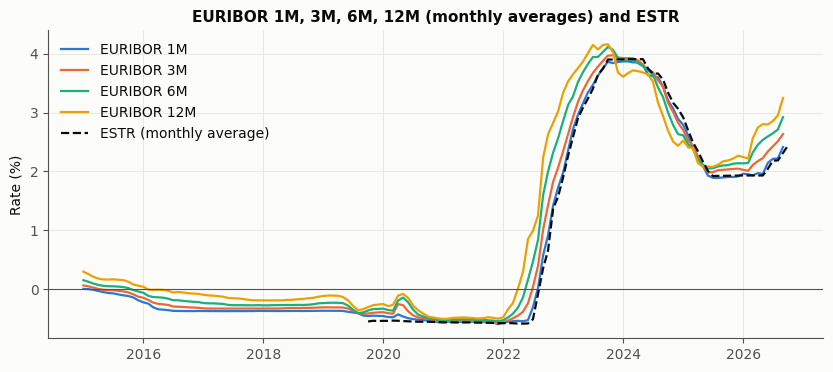

In [3]:
estr_monthly = estr.groupby(estr.index.to_period("M")).mean() * 100
eur = euribor.loc["2015-01":]
fig, ax = plt.subplots(figsize=(10, 4))
for k, col in enumerate(["Euribor1M", "Euribor3M", "Euribor6M", "Euribor12M"]):
    ax.plot(eur.index.to_timestamp(), eur[col], lw=1.6, color=COLORS[k], label=col.replace("Euribor", "EURIBOR "))
ax.plot(estr_monthly.index.to_timestamp(), estr_monthly, lw=1.6, color=INK, ls="--", label="ESTR (monthly average)")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel("Rate (%)"); ax.set_title("EURIBOR 1M, 3M, 6M, 12M (monthly averages) and ESTR"); ax.legend(loc="upper left")
plt.show()

## 3. EURIBOR - €STR basis and proxy quotes (report §4)

### 3.1 Measuring the basis
**Ex post**: for every day $d$, the €STR actually compounded over $[d, d + m]$ (from the ECB €STR index) is averaged over
the month and compared with the monthly average EURIBOR $m$M. This mixes the term premium with the forecast errors of
the market (a fixing set before unexpected hikes looks too low ex post), but needs no model. Only months whose windows are
fully observed are kept.

In [4]:
index = compounded["Index"]
last_day = index.index[-1]

def realised_compounded(months):
    # ESTR compounded over [d, d + months] for every fixing day d (ACT/360, percent)
    out = {}
    for d in index.index:
        e = d + pd.DateOffset(months=months)
        if e > last_day:
            break
        e1 = index.loc[:e].index[-1]
        out[d] = 100 * (index.loc[e1] / index.loc[d] - 1) * 360 / (e1 - d).days
    s = pd.Series(out)
    monthly = s.groupby(s.index.to_period("M")).mean()
    complete = [m for m in monthly.index if (m.to_timestamp(how="end") + pd.DateOffset(months=months)) <= last_day]
    return monthly.loc[complete]

TENOR_MONTHS = {"1M": 1, "3M": 3, "6M": 6, "12M": 12}
basis = pd.DataFrame({t: 100 * (euribor[f"Euribor{t}"] - realised_compounded(m)).dropna() for t, m in TENOR_MONTHS.items()})
by_year = basis.groupby(basis.index.year).mean()
by_year.index.name = "year"
by_year.round(1)

,1M,3M,6M,12M
year,,,,
2019,8.8,13.6,19.3,26.4
2020,4.9,12.4,18.8,25.3
2021,0.7,2,4.7,-0.5
2022,0.2,2.4,-5.5,-53.3
2023,-4.3,-1.2,7.9,11
2024,-5.1,4.7,12.6,30.5
2025,-2.3,10,18.3,20.5
2026,1.5,12.8,17.5,NaN


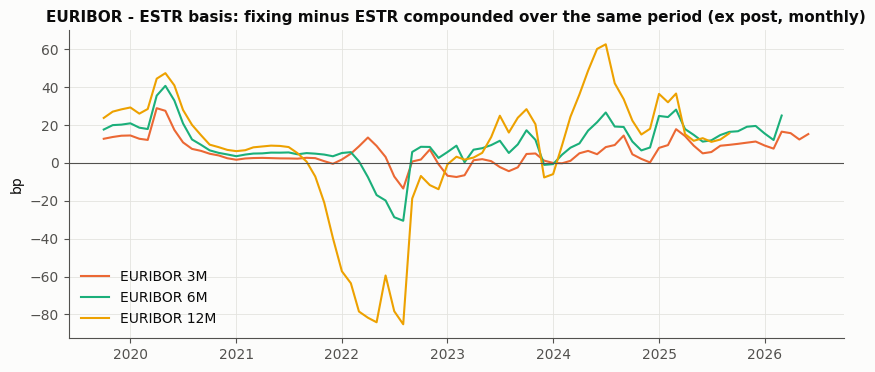

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
for k, t in enumerate(["3M", "6M", "12M"]):
    s = basis[t].dropna()
    ax.plot(s.index.to_timestamp(), s, lw=1.5, color=COLORS[k + 1], label=f"EURIBOR {t}")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel("bp"); ax.legend(loc="lower left")
ax.set_title("EURIBOR - ESTR basis: fixing minus ESTR compounded over the same period (ex post, monthly)")
plt.show()

The ex-post basis is positive and increasing with the tenor in calm periods (5-13bp at 3M and 13-18bp at 6M in
2024-2026). In 2022 it turns negative at 6M and 12M: the fixings were set before hikes the market had not priced, so the
€STR realised afterwards was higher. The 12M series is the noisiest for the same reason.

**Contemporaneous check.** At the valuation date, the last monthly EURIBOR 6M average compared with the 6M €STR OIS rate
of the (proxy) discount curve gives a second, model-dependent, measure.

In [6]:
window = basis.loc[basis.index[-1] - 23:]                    # last 24 complete months
S6_BP, S6_STD = float(window["6M"].mean()), float(window["6M"].std())
S3_BP, S3_STD = float(window["3M"].mean()), float(window["3M"].std())
ois6m = OIS("6M", 0.0).implied_quote(discount)
ois3m = OIS("3M", 0.0).implied_quote(discount)
pd.DataFrame({"ex post, last 24 months (bp)": [S3_BP, S6_BP], "std (bp)": [S3_STD, S6_STD],
              f"EURIBOR {euribor.index[-1]} average (%)": [euribor["Euribor3M"].iloc[-1], euribor["Euribor6M"].iloc[-1]],
              "ESTR OIS on valuation date (%)": [100 * ois3m, 100 * ois6m],
              "contemporaneous (bp)": [100 * euribor["Euribor3M"].iloc[-1] - 1e4 * ois3m, 100 * euribor["Euribor6M"].iloc[-1] - 1e4 * ois6m]},
             index=["3M", "6M"])

,"ex post, last 24 months (bp)",std (bp),EURIBOR 2026-09 average (%),ESTR OIS on valuation date (%),contemporaneous (bp)
3M,9.8966,4.63242,2.63505,2.56262,7.24276
6M,16.6875,5.91313,2.92159,2.71179,20.9806


### 3.2 Term structure of the basis and proxy projection curve
The basis is observed at the fixing tenor only. Assumption: **flat** basis $s_6$ for every forward 6-month period, set
to the ex-post average of the last 24 months. The proxy projection curve is then
$$
P_6(0,t) = P_d(0,t)\,e^{-\tilde s_6\,t},\qquad \tilde s_6 = s_6 \cdot 360/365,
$$
so that every forward 6M EURIBOR is the forward compounded €STR over the same period plus $s_6$ (to first order).

### 3.3 Instruments and proxy quotes
EUR conventions: spot $T+2$ TARGET; floating leg EURIBOR 6M semi-annual ACT/360; fixed leg annual 30E/360; modified
following, no end-of-month rule, dates generated forward from the start; payment at period end. Instruments:
the 6M fixing (deposit on $[T_0, T_0 + 6\mathrm M]$), FRAs $1\times7$ to $12\times18$, and IRS from 2 to 30 years.

In [7]:
def thirty_e_360(d1, d2):
    return (360 * (d2.year - d1.year) + 30 * (d2.month - d1.month) + min(d2.day, 30) - min(d1.day, 30)) / 360

def schedule(start, end_months, step_months):
    # dates generated forward from start, modified following, no end-of-month rule
    return [pd.Timestamp(start)] + [add_months(start, k) for k in range(step_months, end_months + 1, step_months)]

class ProjectionInstrument(Instrument):
    # EURIBOR instrument ; the curve passed to implied_quote is the projection curve (mode "direct") or the
    # spread curve S with P_proj = P_d x S (mode "spread"). discount=None : single curve (the curve also discounts).
    def __init__(self, maturity, quote, discount=None, mode="direct"):
        self.discount, self.mode = discount, mode
        super().__init__(maturity, quote)

    def P_proj(self, curve, t):
        return curve.discount(t) * (self.discount.discount(t) if self.mode == "spread" else 1.0)

    def P_disc(self, curve, t):
        return curve.discount(t) if self.discount is None else self.discount.discount(t)

    def forwards(self, curve, starts, ends, deltas):
        return (self.P_proj(curve, starts) / self.P_proj(curve, ends) - 1) / deltas

class FRA6(ProjectionInstrument):
    # FRA / fixing on [spot + start, spot + start + length] months : quote = forward EURIBOR (ACT/360)
    kind = "FRA"

    def __init__(self, start_months, rate, length=6, **kw):
        s, e = (add_months(SPOT, start_months) if start_months else SPOT), add_months(SPOT, start_months + length)
        self.name = f"{length}M fixing" if start_months == 0 else f"FRA {start_months}x{start_months + length}"
        self.t_s, self.t_e, self.delta = time(s), time(e), (e - s).days / 360
        super().__init__(self.t_e, rate, **kw)

    def implied_quote(self, curve):
        return float(self.forwards(curve, self.t_s, self.t_e, self.delta))

class IRS(ProjectionInstrument):
    # spot-starting swap : fixed annual 30E/360 vs EURIBOR (float_months) ACT/360 ; quote = par rate
    kind = "IRS"

    def __init__(self, years, rate, float_months=6, start=None, **kw):
        start = SPOT if start is None else start
        fixed = schedule(start, 12 * years, 12)
        floating = schedule(start, 12 * years, float_months)
        self.name = f"IRS {years}Y" + ("" if float_months == 6 else f" vs {float_months}M")
        self.t_fix = time(fixed[1:])
        self.d_fix = np.array([thirty_e_360(a, b) for a, b in zip(fixed[:-1], fixed[1:])])
        self.t_s, self.t_e = time(floating[:-1]), time(floating[1:])
        self.d_flt = np.array([(b - a).days / 360 for a, b in zip(floating[:-1], floating[1:])])
        super().__init__(self.t_e[-1], rate, **kw)

    def legs(self, curve):
        annuity = np.sum(self.d_fix * self.P_disc(curve, self.t_fix))
        floating = np.sum(self.d_flt * self.forwards(curve, self.t_s, self.t_e, self.d_flt) * self.P_disc(curve, self.t_e))
        return annuity, floating

    def implied_quote(self, curve):
        annuity, floating = self.legs(curve)
        return floating / annuity

    def value(self, curve, K, payer=True):
        # value per unit notional of a swap paying (payer) the fixed rate K
        annuity, floating = self.legs(curve)
        return (floating - K * annuity) * (1 if payer else -1)

FRA_STARTS = [0, 1, 2, 3, 4, 5, 6, 9, 12]                     # 6M fixing and FRAs 1x7 ... 12x18
IRS_YEARS = [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, 25, 30]

def make_quotes(proj_curve, discount_curve=None, mode="direct", float_months=6, fra_starts=FRA_STARTS, irs_years=IRS_YEARS):
    qs = [FRA6(m, 0.0, length=float_months, discount=discount_curve, mode=mode) for m in fra_starts]
    qs += [IRS(y, 0.0, float_months=float_months, discount=discount_curve, mode=mode) for y in irs_years]
    for q in qs:                                             # quotes = par rates on (proj_curve, discount_curve)
        q.quote = q.implied_quote(proj_curve)
    return qs

class SpreadedCurve:
    # P(t) = P_base(t) exp(-s t) : proxy projection curve
    def __init__(self, base, spread):
        self.base, self.spread = base, spread
    def discount(self, t):
        return self.base.discount(t) * np.exp(-self.spread * np.asarray(t))

def latest_quote_file(prefix="EURIBOR6M_Quotes_"):
    for f in reversed(sorted(glob.glob(os.path.join(DATA, prefix + "[0-9]*.csv")))):
        q = pd.read_csv(f).dropna(subset=["Rate"])
        if len(q):
            return f, q
    return None, None

proxy6 = SpreadedCurve(discount, S6_BP * 1e-4 * 360 / 365)
quote_file, quote_table = latest_quote_file()
if quote_file:
    SOURCE = f"market quotes from {os.path.basename(quote_file)}"
    lookup = dict(zip(quote_table["Instrument"], quote_table["Rate"] / 100))
    quotes = [q for q in make_quotes(proxy6, discount) if q.name in lookup]
    for q in quotes:
        q.quote = lookup[q.name]
else:
    SOURCE = f"PROXY quotes (ESTR proxy curve + flat {S6_BP:.1f}bp basis)"
    quotes = make_quotes(proxy6, discount)
print("Quote source :", SOURCE)
pd.DataFrame({"instrument": [q.name for q in quotes], "pillar (years)": [q.maturity for q in quotes],
              "rate (%)": [100 * q.quote for q in quotes]}).set_index("instrument").T

Quote source : PROXY quotes (ESTR proxy curve + flat 16.7bp basis)


instrument,6M fixing,FRA 1x7,FRA 2x8,FRA 3x9,FRA 4x10,FRA 5x11,FRA 6x12,FRA 9x15,FRA 12x18,IRS 2Y,...,IRS 6Y,IRS 7Y,IRS 8Y,IRS 9Y,IRS 10Y,IRS 12Y,IRS 15Y,IRS 20Y,IRS 25Y,IRS 30Y
pillar (years),0.50411,0.586301,0.671233,0.753425,0.843836,0.923288,1.00548,1.25753,1.50685,2.0137,...,6.01096,7.01096,8.01644,9.0137,10.0137,12.0137,15.0164,20.0219,25.0274,30.0329
rate (%),2.87641,2.96838,3.04007,3.10169,3.15246,3.19317,3.22811,3.29712,3.32854,3.26724,...,3.49967,3.56624,3.63152,3.69237,3.74918,3.84397,3.94595,4.02964,4.04435,4.02168


## 4. Single-curve bootstrap: baseline (report §5)

The same quotes are bootstrapped as in the yield curve notebook: one curve both projects and discounts (`discount=None`).
This checks the instruments with the existing `Bootstrapper` and gives the baseline of Section 6.

In [8]:
def rebind(qs, discount_curve, mode="direct"):
    # same instruments and quotes, other discount curve / mode
    out = []
    for q in qs:
        c = object.__new__(type(q)); c.__dict__.update(q.__dict__); c.discount, c.mode = discount_curve, mode
        out.append(c)
    return out

single = {}
rows = {}
for m in ["raw", "monotone_convex"]:
    boot = Bootstrapper(rebind(quotes, None), method=m)
    single[m] = boot.run()
    rows[m] = {"max residual (bp)": boot.max_residual_bp, "solver": boot.solver, "time (ms)": 1e3 * boot.elapsed}
pd.DataFrame(rows).T

,max residual (bp),solver,time (ms)
raw,4.44089e-12,sequential,32.3367
monotone_convex,4.4062e-12,simultaneous (hybr),512.19


## 5. Dual-curve bootstrap on €STR discounting (report §6)

The instruments hold the €STR curve $P_d$; `implied_quote(curve)` receives the projection curve only, so the existing
`Bootstrapper` solves for $P_6$ unchanged (sequential for raw, simultaneous for monotone convex). A third variant
interpolates the **spread** curve $S = P_6/P_d$ (raw): the €STR steps on ECB dates then pass into the EURIBOR forwards and
only the basis is interpolated.

In [9]:
projection, reports = {}, {}
for name, (mode, method) in {"raw": ("direct", "raw"), "monotone convex": ("direct", "monotone_convex"),
                             "spread over ESTR (raw)": ("spread", "raw")}.items():
    boot = Bootstrapper(rebind(quotes, discount, mode), method=method)
    curve = boot.run()
    projection[name] = (lambda c, m: (lambda t: c.discount(t) * (discount.discount(t) if m == "spread" else 1.0)))(curve, mode)
    reports[name] = boot
pd.DataFrame({n: {"max residual (bp)": b.max_residual_bp, "solver": b.solver, "time (ms)": 1e3 * b.elapsed}
              for n, b in reports.items()}).T

,max residual (bp),solver,time (ms)
raw,4.44089e-12,sequential,32.2361
monotone convex,6.93889e-13,simultaneous (hybr),344.868
spread over ESTR (raw),9.02056e-13,sequential,40.0767


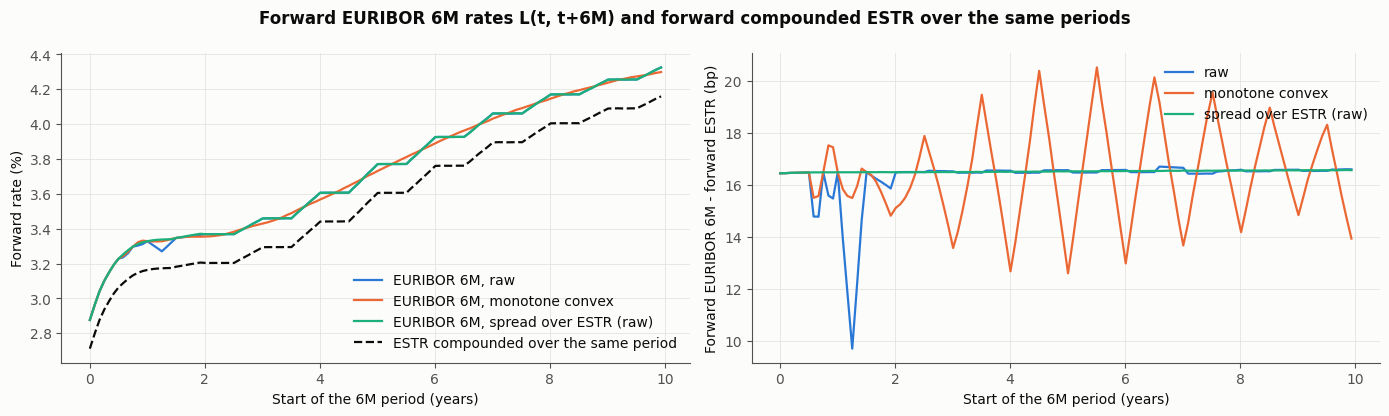

In [10]:
starts = np.array([add_months(SPOT, m) for m in range(0, 120)])
ends = np.array([add_months(SPOT, m + 6) for m in range(0, 120)])
ts, te = time(starts), time(ends)
delta = np.array([(e - s).days / 360 for s, e in zip(starts, ends)])
fwd = lambda P: 100 * (P(ts) / P(te) - 1) / delta
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for k, (name, P) in enumerate(projection.items()):
    axes[0].plot(ts, fwd(P), lw=1.6, color=COLORS[k], label=f"EURIBOR 6M, {name}")
axes[0].plot(ts, fwd(discount.discount), lw=1.6, color=INK, ls="--", label="ESTR compounded over the same period")
axes[0].set_ylabel("Forward rate (%)"); axes[0].legend(loc="lower right")
for k, (name, P) in enumerate(projection.items()):
    axes[1].plot(ts, fwd(P) * 100 - fwd(discount.discount) * 100, lw=1.6, color=COLORS[k], label=name)
axes[1].set_ylabel("Forward EURIBOR 6M - forward ESTR (bp)"); axes[1].legend(loc="upper right")
for ax in axes:
    ax.set_xlabel("Start of the 6M period (years)")
fig.suptitle("Forward EURIBOR 6M rates L(t, t+6M) and forward compounded ESTR over the same periods", fontweight="bold")
plt.tight_layout(); plt.show()

- Interpolating the projection curve itself does not follow the ECB steps of the discount curve, so the forward basis
  moves around $s_6$ purely as an interpolation artefact: with **raw** it dips to about 10bp around 1.25 years (the €STR
  steps fall inside the FRA periods), with **monotone convex** it oscillates by ±4bp around every swap pillar up to
  10 years.
- Interpolating the **spread** keeps the basis smooth and lets the policy path pass into the EURIBOR forwards. Since the
  proxy quotes were generated with a flat basis, this variant recovers it almost exactly; with market quotes it is the
  natural choice for the short end.

### 5.1 Validation
1. **Repricing** of every instrument (above).
2. **Independent repricing with QuantLib**: the €STR and projection curves are passed to QuantLib as discount curves
   (log-linear on the pillar dates, i.e. the same raw interpolation), a EURIBOR 6M swap is built with QuantLib's own
   schedules and day counts (`Thirty360.European`, `Actual360`), and its fair rate is compared with the quote.
3. **Exact round trip**: quotes generated from a known projection curve with raw interpolation on the same pillars are
   bootstrapped back.
4. **Consistency**: with $P_d = $ the single curve, the dual bootstrap gives back the single curve.
5. **Basis**: forward EURIBOR minus forward €STR positive at all maturities.

In [11]:
raw6 = Bootstrapper(rebind(quotes, discount), method="raw").run()
qdate = lambda t: ql.Date(VALUATION.day, VALUATION.month, VALUATION.year) + int(round(365 * t))
today = qdate(0.0); ql.Settings.instance().evaluationDate = today

def ql_curve(curve):
    times = np.concatenate([[0.0], curve.times])
    return ql.YieldTermStructureHandle(ql.DiscountCurve([qdate(t) for t in times], [float(curve.discount(t)) if t > 0 else 1.0 for t in times],
                                                         ql.Actual365Fixed(), ql.TARGET()))

disc_h, proj_h = ql_curve(discount), ql_curve(raw6)
index6 = ql.Euribor6M(proj_h)
qspot = ql.Date(SPOT.day, SPOT.month, SPOT.year)
rows = {}
for q in [q for q in quotes if q.kind == "IRS"]:
    years = int(q.name.split()[1][:-1])
    mat = ql.TARGET().advance(qspot, ql.Period(years, ql.Years), ql.ModifiedFollowing)
    fixed = ql.Schedule(qspot, mat, ql.Period(ql.Annual), ql.TARGET(), ql.ModifiedFollowing, ql.ModifiedFollowing, ql.DateGeneration.Forward, False)
    flt = ql.Schedule(qspot, mat, ql.Period(ql.Semiannual), ql.TARGET(), ql.ModifiedFollowing, ql.ModifiedFollowing, ql.DateGeneration.Forward, False)
    swap = ql.VanillaSwap(ql.VanillaSwap.Payer, 1.0, fixed, q.quote, ql.Thirty360(ql.Thirty360.European), flt, index6, 0.0, ql.Actual360())
    swap.setPricingEngine(ql.DiscountingSwapEngine(disc_h))
    rows[q.name] = {"quote (%)": 100 * q.quote, "QuantLib fair rate (%)": 100 * swap.fairRate(), "difference (bp)": 1e4 * (swap.fairRate() - q.quote)}
qlcheck = pd.DataFrame(rows).T
print(f"QuantLib : max |difference| {qlcheck['difference (bp)'].abs().max():.2e}bp over {len(qlcheck)} swaps")
qlcheck.iloc[[0, 3, 8, -1]]

QuantLib : max |difference| 1.04e-12bp over 14 swaps


,quote (%),QuantLib fair rate (%),difference (bp)
IRS 2Y,3.26724,3.26724,-5.55112e-13
IRS 5Y,3.43309,3.43309,3.46945e-13
IRS 10Y,3.74918,3.74918,4.85723e-13
IRS 30Y,4.02168,4.02168,3.46945e-13


In [12]:
# 3. exact round trip : known projection curve = raw on the same pillars, zero rates = ESTR zero + 20bp
known = YieldCurve(raw6.times, discount.zero_rate(raw6.times) + 0.002, "raw")
rt_quotes = rebind(quotes, discount)
for q in rt_quotes:
    q.quote = q.implied_quote(known)
recovered = Bootstrapper(rt_quotes, method="raw").run()
round_trip = 1e4 * np.max(np.abs(recovered.zero_rates - known.zero_rates))
# 4. P_d = single curve gives back the single curve
consistent = Bootstrapper(rebind(quotes, single["raw"]), method="raw").run()
consistency = 1e4 * np.max(np.abs(consistent.zero_rates - single["raw"].zero_rates))
# 5. basis of the forwards
basis_fwd = {n: fwd(P) - fwd(discount.discount) for n, P in projection.items()}
pd.DataFrame({"criterion": ["max |R_k| < 1e-6 bp", "< 0.01bp", "machine precision", "single-curve result", "positive"],
              "result": [f"{max(b.max_residual_bp for b in reports.values()):.1e} bp",
                         f"{qlcheck['difference (bp)'].abs().max():.1e} bp",
                         f"{round_trip:.1e} bp on the zero rates", f"{consistency:.1e} bp on the zero rates",
                         "min " + ", ".join(f"{n} {100 * b.min():.1f}bp" for n, b in basis_fwd.items())]},
             index=["repricing", "QuantLib", "round trip", "P_d = P_6", "basis"])

,criterion,result
repricing,max |R_k| < 1e-6 bp,4.4e-12 bp
QuantLib,< 0.01bp,1.0e-12 bp
round trip,machine precision,3.7e-12 bp on the zero rates
P_d = P_6,single-curve result,2.5e-12 bp on the zero rates
basis,positive,"min raw 9.7bp, monotone convex 12.6bp, spread ..."


## 6. Single-curve vs dual-curve pricing (report §7)

Both frameworks reprice the par swaps exactly; they differ on everything else. Test instruments (notional EUR 10m),
priced with the single raw curve and with (€STR, raw projection):

In [13]:
NOTIONAL = 10_000_000
tests = {
    "IRS 10Y at par (quote)": (IRS(10, 0.0), None),
    "IRS 5Y payer, K = 2.00%": (IRS(5, 0.0), 0.02),
    "IRS 5Y payer, K = 4.00%": (IRS(5, 0.0), 0.04),
    "IRS 30Y payer, K = 2.50%": (IRS(30, 0.0), 0.025),
    "fwd 2Y x 3Y payer, K = 3.00%": (IRS(3, 0.0, start=add_months(SPOT, 24)), 0.03),
    "fwd 5Y x 5Y payer, K = 3.50%": (IRS(5, 0.0, start=add_months(SPOT, 60)), 0.035),
}
rows = {}
for name, (inst, K) in tests.items():
    s = rebind([inst], None)[0]; d = rebind([inst], discount)[0]
    K = s.implied_quote(single["raw"]) if K is None else K
    vs, vd = NOTIONAL * s.value(single["raw"], K), NOTIONAL * d.value(raw6, K)
    rows[name] = {"par rate single (%)": 100 * s.implied_quote(single["raw"]), "par rate dual (%)": 100 * d.implied_quote(raw6),
                  "value single (EUR)": vs, "value dual (EUR)": vd, "difference (EUR)": vd - vs, "difference (bp of N)": 1e4 * (vd - vs) / NOTIONAL}
fra = FRA6(15, 0.0)
rows["FRA 15x21 rate"] = {"par rate single (%)": 100 * rebind([fra], None)[0].implied_quote(single["raw"]),
                          "par rate dual (%)": 100 * rebind([fra], discount)[0].implied_quote(raw6)}
pd.DataFrame(rows).T

,par rate single (%),par rate dual (%),value single (EUR),value dual (EUR),difference (EUR),difference (bp of N)
IRS 10Y at par (quote),3.74918,3.74918,0,2.77556e-09,2.77556e-09,2.77556e-12
"IRS 5Y payer, K = 2.00%",3.43309,3.43309,"649,626","652,767","3,141.66",3.14166
"IRS 5Y payer, K = 4.00%",3.43309,3.43309,"-256,985","-258,228","-1,242.81",-1.24281
"IRS 30Y payer, K = 2.50%",4.02168,4.02168,2.64096e+06,2.6966e+06,"55,634.2",55.6342
"fwd 2Y x 3Y payer, K = 3.00%",3.55465,3.55415,"145,617","146,441",823.73,0.82373
"fwd 5Y x 5Y payer, K = 3.50%",4.131,4.12787,"236,798","238,719","1,921.86",1.92186
FRA 15x21 rate,3.26782,3.27015,NaN,NaN,NaN,NaN


- The par swap is worth zero in both frameworks, by construction.
- Off-market swaps differ: the single curve discounts at EURIBOR (above €STR), so it **understates the PV** of the
  fixed-minus-floating difference; the error grows with the moneyness and the maturity.
- Forward-starting swaps and FRAs between pillars differ in their **rates**, not only their values: the single curve
  makes the forwards depend on how the floating leg telescopes on a curve that also discounts.

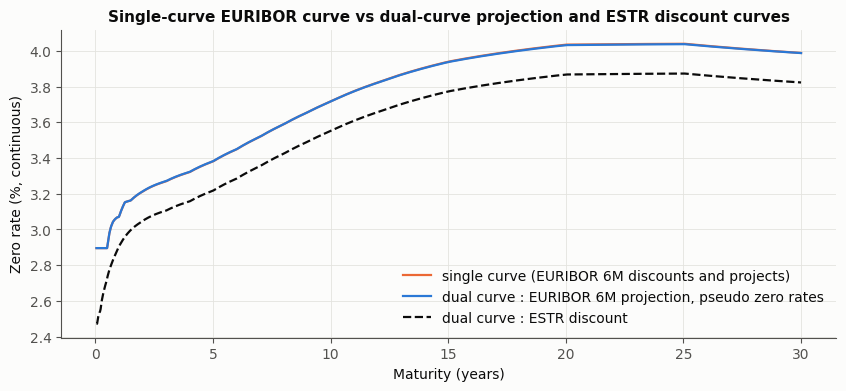

In [14]:
t = np.linspace(0.05, 30, 1200)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, 100 * single["raw"].zero_rate(t), lw=1.6, color=COLORS[1], label="single curve (EURIBOR 6M discounts and projects)")
ax.plot(t, 100 * raw6.zero_rate(t), lw=1.6, color=COLORS[0], label="dual curve : EURIBOR 6M projection, pseudo zero rates")
ax.plot(t, 100 * discount.zero_rate(t), lw=1.6, color=INK, ls="--", label="dual curve : ESTR discount")
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Zero rate (%, continuous)"); ax.legend(loc="lower right")
ax.set_title("Single-curve EURIBOR curve vs dual-curve projection and ESTR discount curves"); plt.show()

## 7. Tenor basis: the EURIBOR 3M curve (report §8)

Same construction for the 3M index: proxy projection curve = €STR curve + flat ex-post 3M basis $s_3$, quotes = 3M fixing,
FRAs $1\times4$ to $18\times21$ and IRS 2-10 years against EURIBOR 3M (quarterly ACT/360 floating leg). Both projection
curves are bootstrapped as a **spread over €STR** (raw): interpolating the 3M and 6M curves directly, with different
pillars, creates a spurious tenor basis of about ±10bp between the 3M swap pillars. The **3M/6M
tenor basis** is the difference between a forward 6M EURIBOR and the 3M forwards compounded over the same 6 months.

EURIBOR 3M curve : 14 instruments, max residual 8.8e-12bp


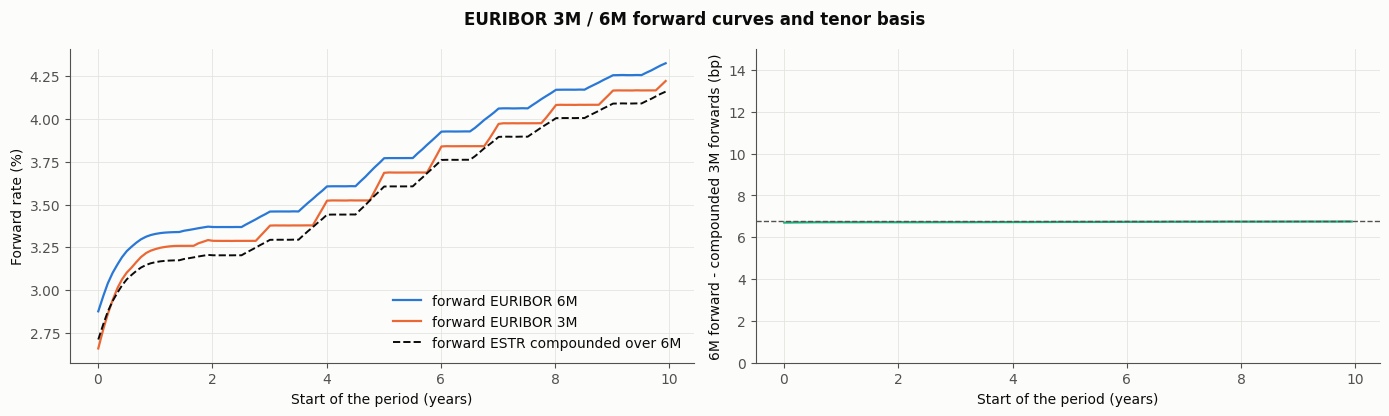

tenor basis : mean 6.7bp (s6 - s3 = 6.8bp)


In [15]:
proxy3 = SpreadedCurve(discount, S3_BP * 1e-4 * 360 / 365)
quotes3 = make_quotes(proxy3, discount, float_months=3, fra_starts=[0, 1, 3, 6, 9, 12, 15, 18], irs_years=[2, 3, 4, 5, 7, 10])
# both projection curves as a spread over ESTR (raw), so that the ESTR steps cancel in the tenor basis (Section 5)
boot3 = Bootstrapper(rebind(quotes3, discount, "spread"), method="raw"); spread3 = boot3.run()
spread6 = Bootstrapper(rebind(quotes, discount, "spread"), method="raw").run()
P3 = lambda t: spread3.discount(t) * discount.discount(t)
P6 = lambda t: spread6.discount(t) * discount.discount(t)
print(f"EURIBOR 3M curve : {len(quotes3)} instruments, max residual {boot3.max_residual_bp:.1e}bp")

def compounded_3m(P, s, e):
    m = add_months(s, 3)
    t0, t1, t2 = time(s), time(m), time(e)
    d1, d2 = (m - s).days / 360, (e - m).days / 360
    f1, f2 = (P(t0) / P(t1) - 1) / d1, (P(t1) / P(t2) - 1) / d2
    return ((1 + f1 * d1) * (1 + f2 * d2) - 1) / ((e - s).days / 360)

l6 = fwd(P6)
l3c = np.array([100 * compounded_3m(P3, s, e) for s, e in zip(starts, ends)])
l3 = 100 * (P3(ts) / P3(time([add_months(s, 3) for s in starts])) - 1) / np.array([(add_months(s, 3) - s).days / 360 for s in starts])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(ts, l6, lw=1.6, color=COLORS[0], label="forward EURIBOR 6M")
axes[0].plot(ts, l3, lw=1.6, color=COLORS[1], label="forward EURIBOR 3M")
axes[0].plot(ts, fwd(discount.discount), lw=1.4, color=INK, ls="--", label="forward ESTR compounded over 6M")
axes[0].set_ylabel("Forward rate (%)"); axes[0].legend(loc="lower right")
axes[1].plot(ts, 100 * (l6 - l3c), lw=1.6, color=COLORS[2])
axes[1].axhline(S6_BP - S3_BP, color=MUTED, lw=1, ls="--")
axes[1].set_ylabel("6M forward - compounded 3M forwards (bp)"); axes[1].set_ylim(0, 15)
for ax in axes:
    ax.set_xlabel("Start of the period (years)")
fig.suptitle("EURIBOR 3M / 6M forward curves and tenor basis", fontweight="bold"); plt.tight_layout(); plt.show()
print(f"tenor basis : mean {100 * np.mean(l6 - l3c):.1f}bp (s6 - s3 = {S6_BP - S3_BP:.1f}bp)")

With flat proxy bases the tenor basis is flat at about $s_6 - s_3 \approx 7$bp, as expected (it is only consistent with
the inputs because both curves interpolate a spread). With market quotes (3s6s basis swaps) the tenor basis would be an input of its own.

## 8. Risk: par-point sensitivities to both curves (report §9)

An **18m × 4y forward payer swap** against EURIBOR 6M (fixed 3%, EUR 10m). Bumping an €STR OIS quote moves the discount
curve **and** the projection curve (the EURIBOR quotes are held fixed, so $P_6$ is re-bootstrapped on the new $P_d$);
bumping a EURIBOR quote moves the projection curve only. "Via projection" is the part of an €STR bump that goes through
the re-bootstrapped projection curve (total minus the effect of the new discount curve with $P_6$ frozen).

In [16]:
trade = rebind([IRS(4, 0.0, start=add_months(SPOT, 18))], discount)[0]
K = 0.03

def value(disc_curve, proj_curve):
    t = rebind([trade], disc_curve)[0]
    return NOTIONAL * t.value(proj_curve, K)

def projection_on(disc_curve, qs=quotes):
    return Bootstrapper(rebind(qs, disc_curve), method="raw").run()

base = value(discount, raw6)
rows = {}
start = clock.time()
for i, q in enumerate(ois_quotes):
    bumped = [OIS(x.tenor, x.quote + (1e-4 if j == i else 0.0)) for j, x in enumerate(ois_quotes)]
    d = estr_curve_from(bumped)
    total = value(d, projection_on(d)) - base
    frozen = value(d, raw6) - base
    rows[f"ESTR {q.tenor}"] = {"DV01 (EUR)": total, "of which via projection": total - frozen}
for i, q in enumerate(quotes):
    bumped = rebind(quotes, discount)
    bumped[i].quote += 1e-4
    rows[f"EURIBOR {q.name}"] = {"DV01 (EUR)": value(discount, Bootstrapper(bumped, method="raw").run()) - base,
                                 "of which via projection": np.nan}
d_all = estr_curve_from([OIS(x.tenor, x.quote + 1e-4) for x in ois_quotes])
up_all = rebind(quotes, d_all)
for q in up_all:
    q.quote += 1e-4
rows["parallel +1bp (both curves)"] = {"DV01 (EUR)": value(d_all, Bootstrapper(up_all, method="raw").run()) - base,
                                       "of which via projection": np.nan}
risk = pd.DataFrame(rows).T
print(f"Value {base:,.0f} EUR | {len(rows)} revaluations in {clock.time() - start:.1f}s | "
      f"sum of par points {risk['DV01 (EUR)'].iloc[:-1].sum():,.0f} EUR")
risk[risk["DV01 (EUR)"].abs() > 1].round(0)

Value 202,423 EUR | 49 revaluations in 3.8s | sum of par points 3,412 EUR


,DV01 (EUR),of which via projection
ESTR 6M,7,7
ESTR 1Y,-15,-16
ESTR 18M,22,23
ESTR 2Y,-36,-17
ESTR 3Y,-12,-0
ESTR 4Y,-16,4
ESTR 5Y,-42,-10
ESTR 6Y,13,-16
EURIBOR 6M fixing,-499,NaN
EURIBOR FRA 6x12,-494,NaN


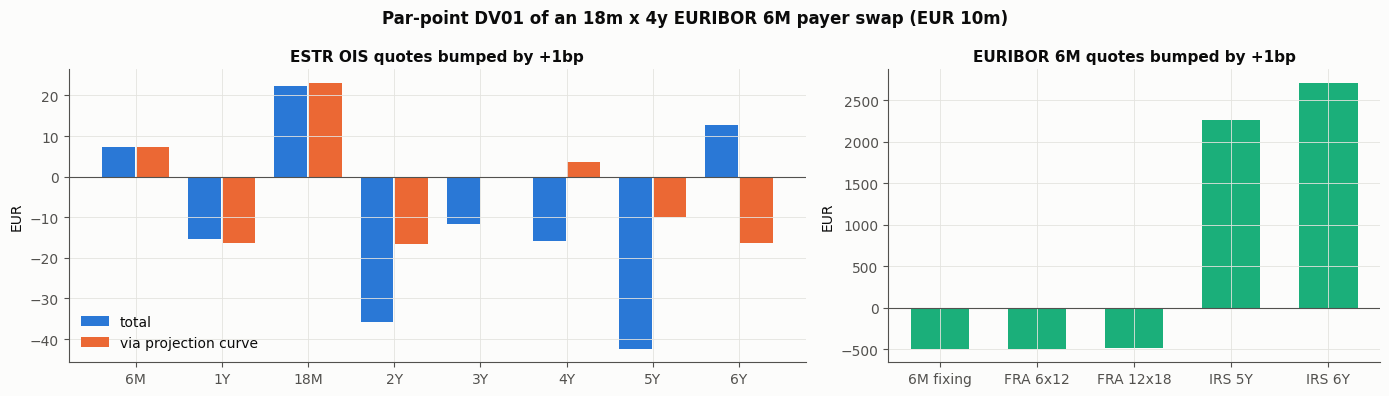

In [17]:
estr_part = risk.loc[[i for i in risk.index if i.startswith("ESTR")]]
eur_part = risk.loc[[i for i in risk.index if i.startswith("EURIBOR")]]
estr_part = estr_part[estr_part["DV01 (EUR)"].abs() > 1]
eur_part = eur_part[eur_part["DV01 (EUR)"].abs() > 1]
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [len(estr_part) + 1, len(eur_part) + 1]})
x = np.arange(len(estr_part))
axes[0].bar(x - 0.2, estr_part["DV01 (EUR)"], width=0.38, color=COLORS[0], label="total")
axes[0].bar(x + 0.2, estr_part["of which via projection"], width=0.38, color=COLORS[1], label="via projection curve")
axes[0].set_xticks(x); axes[0].set_xticklabels([i.replace("ESTR ", "") for i in estr_part.index])
axes[0].set_title("ESTR OIS quotes bumped by +1bp"); axes[0].legend(loc="lower left")
x = np.arange(len(eur_part))
axes[1].bar(x, eur_part["DV01 (EUR)"], width=0.6, color=COLORS[2])
axes[1].set_xticks(x); axes[1].set_xticklabels([i.replace("EURIBOR ", "") for i in eur_part.index])
axes[1].set_title("EURIBOR 6M quotes bumped by +1bp")
for ax in axes:
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_ylabel("EUR")
fig.suptitle("Par-point DV01 of an 18m x 4y EURIBOR 6M payer swap (EUR 10m)", fontweight="bold")
plt.tight_layout(); plt.show()

- The **outright rate risk** sits on the EURIBOR quotes: positive on the IRS 5Y and 6Y that bracket the end of the swap
  (a payer gains when long rates rise), negative on the instruments that fix its start at 18 months. With raw
  interpolation and sequential pillars, $P_6(0, 1.5)$ is pinned by the chain 6M fixing, FRA 6x12, FRA 12x18, so each
  of the three carries about the same -490 EUR.
- The €STR quotes carry only tens of EUR, against thousands on the EURIBOR quotes: with the EURIBOR quotes held fixed,
  the projection curve is re-bootstrapped and only the discounting of the net value of the trade moves, much of it
  through the re-bootstrapped projection curve. Moving €STR with EURIBOR fixed is a move of the **EURIBOR - €STR
  basis**, and this trade carries little basis risk.
- The parallel move of both curves equals the sum of the par points (raw interpolation is linear in the quotes).

## 9. Conclusions and limitations (report §10-12)

- The dual-curve bootstrap reuses the existing `Bootstrapper`: the instruments carry the discount curve and expose
  `implied_quote(projection_curve)`. It reprices every quote to machine precision and agrees with QuantLib's own swap
  pricer; the round trip and the single-curve limit are exact.
- Interpolating the **spread over €STR** rather than the projection curve keeps the ECB steps in the EURIBOR forwards and
  a smooth basis.
- **Proxy quotes**: the EURIBOR - €STR basis is measured ex post on monthly averages (it includes forecast errors) and
  assumed flat in maturity; the €STR curve is itself a proxy. Fill `Data/EUR/EURIBOR6M_Quotes_YYYYMMDD.csv` (columns
  `Instrument`, `Rate` in percent, instrument names as in Section 3.3) to use market quotes.
- Not modelled: EURIBOR 3M futures and their convexity adjustment, 1Y swaps against 3M, end-of-month rule and stubs, the
  EURIBOR fallback to €STR.